# Random Forest

This notebook will use Random Forest to predict expert players and plateaued players. Random Forest is an ensemble classifier. Instead of using a single decision tree, random forest generates a whole forest of trees by splitting the training data randomly for each tree. Each tree will be different to every other tree. The output is the mode of the output of all individual trees.

Random forest is usually better than a single decision tree. I will see is this the case for my dataset below.

First, import CSV as usual:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chess_rating_plateau.csv')
print("Read CSV successful")
SEED = 42

Imports successful
Read CSV successful


## Generate Random Forest

As with the decision trees, first I drop the unnecessary and/or redundant columns. Then the data is split into train and test sets. A random forest is then generated from the training set. The default 100 estimators are used in this case. Increasing this amount brought no benefits.

Finally, a classification report, confusion matrix, precision recall curve, feature importances and depths of the trees are displayed.

In [2]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

drop = ["player_id", "peak_rating", "plateaued", "reached_expert", "deliberate_hours", "age_now"]
features = [c for c in csv.columns if c not in drop]
X = csv[features]

def get_random_forest(target):
    y = csv[target]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

    random_forest = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
    random_forest.fit(X_train, y_train)

    print(classification_report(y_test, random_forest.predict(X_test)))

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_estimator(random_forest, X_test, y_test, ax=ax[0], cmap='Reds')
    ax[0].grid(False)
    ax[0].set_title("Confusion Matrix")
    PrecisionRecallDisplay.from_estimator(random_forest, X_test, y_test, ax=ax[1])
    ax[1].set_title("Precision Recall Curve")
    plt.show()

    print('Feature importances:')
    print(pd.Series(random_forest.feature_importances_, index=features).sort_values(ascending=False))

    depths = [tree.get_depth() for tree in random_forest.estimators_]
    print("Max depth:", max(depths))
    print("Mean depth:", np.mean(depths))
    print("Min depth:", min(depths))

    return random_forest

## Expert Random Forest

text and waffle


              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7200
           1       0.83      0.68      0.75      1800

    accuracy                           0.91      9000
   macro avg       0.88      0.82      0.84      9000
weighted avg       0.90      0.91      0.90      9000



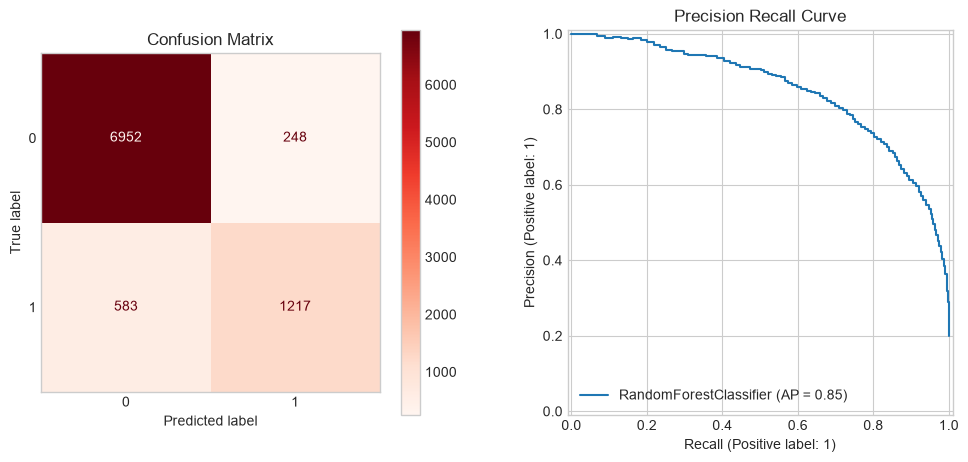

Feature importances:
games_played              0.206809
cognitive_ability         0.197040
deliberate_share          0.138901
tactics_training_hours    0.120856
starting_age              0.079638
analyzes_own_games        0.077409
total_study_hours         0.068332
opening_study_hours       0.050088
years_playing             0.043599
studies_endgames          0.009194
has_coach                 0.008133
dtype: float64
Max depth: 28
Mean depth: 23.33
Min depth: 21


In [3]:
expert_forest = get_random_forest('reached_expert')

## Plateaued Random Forest

text and waffle

              precision    recall  f1-score   support

           0       0.65      0.83      0.73      5505
           1       0.53      0.30      0.38      3495

    accuracy                           0.62      9000
   macro avg       0.59      0.56      0.56      9000
weighted avg       0.60      0.62      0.59      9000



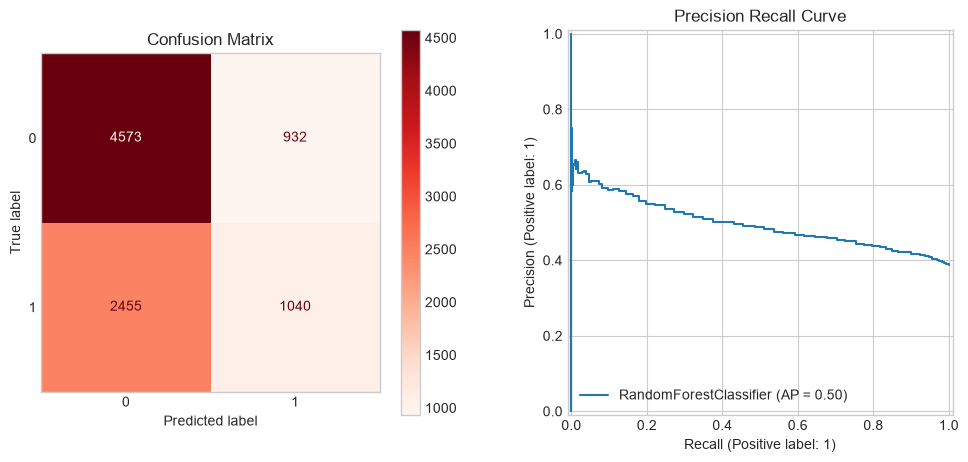

Feature importances:
deliberate_share          0.136340
games_played              0.133054
analyzes_own_games        0.120652
cognitive_ability         0.117038
total_study_hours         0.105752
opening_study_hours       0.096227
starting_age              0.090286
years_playing             0.085466
tactics_training_hours    0.084978
studies_endgames          0.016776
has_coach                 0.013433
dtype: float64
Max depth: 43
Mean depth: 36.58
Min depth: 31


In [4]:
plateaued_forest = get_random_forest('plateaued')

## Conclusion

text and waffle
